<a href="https://colab.research.google.com/github/Maulanaputra07/number-classification-KNN-model/blob/main/Classification_number_with_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Jalankan perintah ini untuk menginstal library baru (contoh: opencv-python)
# Anda bisa mengganti nama library sesuai kebutuhan Anda
!pip install -q gradio

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

#Mengunduh dataset MNIST
print("Fetch MNIST dataset")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')

x = mnist.data  # data gambar (70.000 baris x 784 kolom piksel)
y = mnist.target

print(f"Bentuk data gambar (x): {x.shape}")
print(f"Bentuk data label (y): {y.shape}")

Fetch MNIST dataset
Bentuk data gambar (x): (70000, 784)
Bentuk data label (y): (70000,)


## Visualisasikan data (melihat apa yang dilihat oleh komputer)

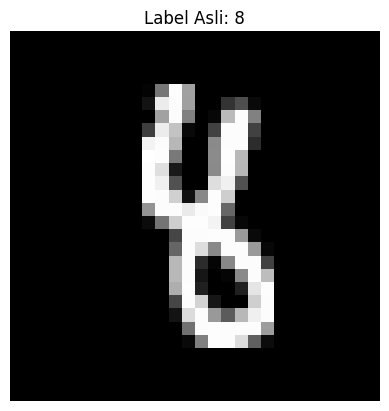

In [ ]:
contoh_gambar = x[7000].reshape(28, 28)
label_asli = y [7000]

plt.imshow(contoh_gambar, cmap='gray')
plt.title(f"Label Asli: {label_asli}")
plt.axis('off')
plt.show()

## Normalisasi dan pembagian data (Train-test split)

Nilai piksel asli adalah 0 sampai 255. Kita bagi dengan 255.0 agar rentangnya menjadi 0.0 sampai 1.0 (proses ini disebut Normalisasi agar perhitungan jarak lebih efisien dan seragam).

In [ ]:
x_normalized = x / 255.0

x_train, x_test, y_train, y_test = train_test_split(
    x_normalized, y, test_size=10000, random_state=42
)

print(f"Jumlah data dilatih: {len(x_train)}")
print(f"Jumlah data diuji: {len(x_test)}")

Jumlah data dilatih: 60000
Jumlah data diuji: 10000


## Melatih model dan Evaluasi Akurasi

Sekarang kita terapkan rumus Euclidean Distance menggunakan KNeighborsClassifier dengan mencari $K = 3$ tetangga terdekat.

In [ ]:
# 1. Inisialisasi algoritma KNN dengan K=3
model_knn = KNeighborsClassifier(n_neighbors=3, metric='euclidean')

# 2. Proses "Belajar" (Menyimpan peta data latih ke memori)
print('Melatih model KNN')
model_knn.fit(x_train, y_train)

# 3. Proses "Ujian" (Memprediksi 1.000 data uji pertama agar proses cepat)
print('Menguji akurasi model')
y_pred = model_knn.predict(x_test[:1000])

# 4. Hitung persentase tebakan yang benar
akurasi = accuracy_score(y_test[:1000], y_pred)
print(f"Akurasi model KNN: {akurasi * 100:.2f}%")

Melatih model KNN
Menguji akurasi model
Akurasi model KNN: 97.80%


## Pengujian gagal model KNN

KNN memiliki kelemahan fatal: jika Anda mencoret angka agak bergeser sedikit saja ke kiri atau kanan, akurasinya langsung anjlok karena perbandingan piksel-per-pikselnya tidak lagi sejajar.

In [ ]:
# Menggeser salah satu gambar uji sejauh 3 piksel ke kanan
gambar_asli = x_test[0].reshape(28, 28)
gambar_digeser = np.roll(gambar_asli, shift=3, axis=1) # geser ke kanan

# Prediksi ulang dengan model KNN yang sudah dilatih
prediksi_asli = model_knn.predict([gambar_asli.flatten()])[0]
prediksi_geser = model_knn.predict([gambar_digeser.flatten()])[0]

print(f"Label Sebenarnya : {y_test[0]}")
print(f"Tebakan Asli     : {prediksi_asli}")
print(f"Tebakan Digeser  : {prediksi_geser}") # Sering kali langsung salah!

Label Sebenarnya : 8
Tebakan Asli     : 8
Tebakan Digeser  : 5


Penyebabnya: KNN membandingkan piksel secara kaku berdasarkan koordinat (piksel baris 5 kolom 10 dibandingkan dengan baris 5 kolom 10). Begitu garis bergeser 3 kotak saja, nilai Euclidean Distance-nya melonjak drastis sehingga komputer menganggapnya sebagai gambar yang sama sekali berbeda.

## Integrasi dengan Web Canvas Sederhana di Colab

Kita akan membuat sebuah canvas HTML5 interaktif. Anda dapat menggambar angka menggunakan mouse atau layar sentuh. Ketika Anda menekan tombol **Prediksi**, gambar dari canvas akan dikirim kembali ke Python, diubah ukurannya menjadi $28 \times 28$ piksel, dinormalisasi, dan diprediksi menggunakan model KNN (`model_knn`) yang telah Anda latih.

In [ ]:
import gradio as gr
import numpy as np
from PIL import Image, ImageOps

def prediksi_angka_knn(gambar_kanvas):
    if gambar_kanvas is None:
        return "Silahkan coret angka terlebih dahulu"

    # Ambil gambar dari canvas
    img_array = gambar_kanvas["composite"]

    # Ubah ke mode Grayscale
    img = Image.fromarray(img_array).convert("L")

    # Invert warna karena canvas Gradio menghasilkan latar transparan/putih dan coretan hitam,
    # sedangkan MNIST membutuhkan latar belakang hitam dengan coretan putih.
    img_inverted = ImageOps.invert(img)

    # Resize gambar menjadi 28x28 piksel
    img_resized = img_inverted.resize((28, 28), Image.Resampling.LANCZOS)

    # Normalisasi nilai piksel (0.0 sampai 1.0)
    img_final = np.array(img_resized) / 255.0
    img_flat = img_final.reshape(1, 784)

    # Ambil probabilitas untuk masing-masing kelas (0-9)
    probabilitas = model_knn.predict_proba(img_flat)[0]

    # Buat format dictionary { "label": nilai_probabilitas }
    label_prob = {str(i): float(probabilitas[i]) for i in range(10)}

    return label_prob

# Membuka interface Gradio baru
ui = gr.Interface(
    fn = prediksi_angka_knn,
    inputs = gr.Sketchpad(
        label = " Coret Angka (0-9) di tengah kotak",
        type = "numpy",
        brush = gr.Brush(default_size = 18, colors=["#000000"], color_mode="Fixed")
    ),
    outputs = gr.Label(num_top_classes=3, label="Hasil prediksi model KNN"),
    title = " Uji coba deteksi angka menggunakan algoritma KNN",
    description = " Coba menulis angka di tengah kanvas, lalu bandingkan hasilnya "
)

ui.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b4ea95fe46c08ab98e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://166322b59b7d52eb19.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://b4ea95fe46c08ab98e.gradio.live


## Pengoptimalan Model KNN pada integrasi web kanvas

In [ ]:
import gradio as gr
import numpy as np
from PIL import Image, ImageOps
from scipy import ndimage
from sklearn.neighbors import KNeighborsClassifier

# 1. Optimasi Hyperparameter KNN: gunakan K=5 dan pembobotan berdasarkan jarak
print("Melatih ulang model KNN dengan pembobotan jarak...")
model_knn_opt = KNeighborsClassifier(n_neighbors=5, weights='distance', metric='euclidean', n_jobs=-1)
model_knn_opt.fit(x_train, y_train)

def preprocessing_ala_mnist(img_pil):
    # Konversi ke grayscale dan invert (latar hitam = 0, tinta putih = 255)
    img = img_pil.convert("L")
    img_inv = ImageOps.invert(img)
    arr = np.array(img_inv)

    # Cari koordinat piksel yang memiliki tinta (nilai > 20 untuk buang noise tipis)
    coords = np.argwhere(arr > 20)
    if len(coords) == 0:
        return np.zeros((28, 28))

    # 1. Auto-Crop: Potong area kosong di sekeliling angka
    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0) + 1
    cropped = arr[y_min:y_max, x_min:x_max]

    # 2. Resize proporsional agar sisi terpanjang menjadi 20 piksel (standar MNIST)
    h, w = cropped.shape
    if h > w:
        new_h = 20
        new_w = max(1, int(round((w / h) * 20)))
    else:
        new_w = 20
        new_h = max(1, int(round((h / w) * 20)))

    img_cropped = Image.fromarray(cropped).resize((new_w, new_h), Image.Resampling.LANCZOS)
    arr_20 = np.array(img_cropped)

    # 3. Tempelkan ke tengah kanvas kosong 28x28
    kanvas_28 = np.zeros((28, 28))
    pad_y = (28 - new_h) // 2
    pad_x = (28 - new_w) // 2
    kanvas_28[pad_y:pad_y+new_h, pad_x:pad_x+new_w] = arr_20

    # 4. Geser berdasarkan Center of Mass (titik berat tinta) agar presisi seperti MNIST
    cy, cx = ndimage.center_of_mass(kanvas_28)
    shift_y = np.round(14.0 - cy).astype(int)
    shift_x = np.round(14.0 - cx).astype(int)
    kanvas_28 = ndimage.shift(kanvas_28, shift=[shift_y, shift_x], mode='constant', cval=0.0)

    # Normalisasi (0 - 1)
    return kanvas_28 / 255.0

def prediksi_knn_optimal(gambar_kanvas):
    if gambar_kanvas is None:
        return {}, None

    img_array = gambar_kanvas["composite"]
    img_pil = Image.fromarray(img_array)

    # Terapkan preprocessing standar MNIST
    img_siap = preprocessing_ala_mnist(img_pil)
    img_flat = img_siap.reshape(1, 784)

    # Prediksi probabilitas dengan model KNN yang sudah dioptimasi
    probabilitas = model_knn_opt.predict_proba(img_flat)[0]
    label_prob = {str(i): float(probabilitas[i]) for i in range(10)}

    # Kembalikan juga gambar 28x28 hasil preprocessing agar Anda bisa melihat apa yang dilihat model
    return label_prob, Image.fromarray((img_siap * 255).astype(np.uint8)).resize((140, 140), Image.Resampling.NEAREST)

# Bangun ulang antarmuka Gradio dengan preview hasil preprocessing
antarmuka_opt = gr.Interface(
    fn=prediksi_knn_optimal,
    inputs=gr.Sketchpad(
        label="Coret Angka (0-9) di Mana Saja di Dalam Kotak",
        type="numpy",
        brush=gr.Brush(default_size=16, colors=["#000000"], color_mode="fixed")
    ),
    outputs=[
        gr.Label(num_top_classes=3, label="Hasil Prediksi Model KNN (Optimal)"),
        gr.Image(label="Input 28x28 Setelah Auto-Crop & Centering (Yang Dilihat Model)")
    ],
    title="Deteksi Angka KNN + Smart Preprocessing MNIST",
    description="Sekarang coba tulis angka kecil di pojok kanvas! Perhatikan kotak kanan bawah yang otomatis memotong dan memusatkan angka Anda."
)

antarmuka_opt.launch(share=True, debug=True)

Melatih ulang model KNN dengan pembobotan jarak...
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://6e4bec9289b0cafbcb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://6e4bec9289b0cafbcb.gradio.live
